In [1]:
import sys, pathlib
sys.path.append(str(pathlib.Path().resolve().parent))
from src.graph_utils import plot_weighted_graph, compute_Q, ktte,kttw
from src.graph_dataset_preparation import load_mutag, add_uniform_weights, ensure_unique_edge_weights

In [2]:

graphs = load_mutag("datasets/mutag")
print(len(graphs))
graphs_w_weights = add_uniform_weights(graphs)
unique_weighted_graphs = ensure_unique_edge_weights(graphs_w_weights)

188


In [3]:
import numpy as np

labels = np.loadtxt(
    "/Users/gregorioperez/Documents/Maestria/Investigacion/graph kernels/datasets/mutag/MUTAG_graph_labels.txt",
    dtype=np.int64
)

print(type(labels), labels.shape)


<class 'numpy.ndarray'> (188,)


In [4]:
from sklearn.model_selection import train_test_split
G_train, G_test, y_train, y_test = train_test_split(unique_weighted_graphs, labels, test_size=0.2, random_state=50)


In [5]:
import numpy as np

n_train = len(G_train)
n_test = len(G_test)

kts = np.zeros((n_train, n_train), dtype=float)
kts_test = np.zeros((n_test, n_train), dtype=float)


In [6]:
for i in range(n_train):
    for j in range(n_train):
        Q1 = compute_Q(G_train[i])
        Q2 = compute_Q(G_train[j])
        kts[i, j] = kttw(Q1, Q2, gamma=0.5, strategy='pad')

for i in range(n_test):
    for j in range(n_train):
        Q1 = compute_Q(G_test[i])
        Q2 = compute_Q(G_train[j])
        kts_test[i, j] = kttw(Q1, Q2, gamma=0.5,  strategy='pad')


[(3, 2), (1, 0), (17, 16), (8, 9), (8, 7), (2, 7), (7, 6), (4, 5), (18, 16), (8, 10), (6, 5), (12, 13), (10, 15), (6, 11), (0, 9), (12, 11), (16, 13), (14, 15), (10, 11), (13, 14), (1, 2), (3, 4)]
[[ 0.  0.  0.  0.  1.  0.  1.  0.  0. -1.  0.  0.  0.  1.  0.  0.  0.  0.
   1.  0.  0.  0.]
 [ 0.  0.  0.  0. -1.  0. -1.  0.  0.  1.  0. -1.  1. -1.  0.  1.  0. -1.
   0.  1.  0.  0.]
 [ 0.  1.  0. -1.  1. -1.  0.  0.  0.  0.  0.  0.  0.  0.  1.  0.  0.  0.
   0.  0.  1.  0.]
 [ 1.  0.  0.  0.  0.  1.  1. -1.  0.  0.  1.  0.  0.  0.  0.  0.  0.  0.
   0.  0.  0.  1.]]
[(3, 2), (1, 0), (17, 16), (8, 9), (8, 7), (2, 7), (7, 6), (4, 5), (18, 16), (8, 10), (6, 5), (12, 13), (10, 15), (6, 11), (0, 9), (12, 11), (16, 13), (14, 15), (10, 11), (13, 14), (1, 2), (3, 4)]
[[ 0.  0.  0.  0.  1.  0.  1.  0.  0. -1.  0.  0.  0.  1.  0.  0.  0.  0.
   1.  0.  0.  0.]
 [ 0.  0.  0.  0. -1.  0. -1.  0.  0.  1.  0. -1.  1. -1.  0.  1.  0. -1.
   0.  1.  0.  0.]
 [ 0.  1.  0. -1.  1. -1.  0.  0.  0.  0.  0.  

In [11]:
from sklearn.svm import SVC
clf = SVC(C=1.0, kernel='precomputed')
clf.fit(kts, y_train)
SVC(kernel='precomputed')
y_pred = clf.predict(kts_test)

In [12]:
from sklearn.metrics import accuracy_score
print("%2.2f %%" %(round(accuracy_score(y_test, y_pred)*100)))

79.00 %


In [13]:
import numpy as np
from sklearn.decomposition import KernelPCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    confusion_matrix,
    accuracy_score,
)
from scipy.optimize import linear_sum_assignment

# Do not mutate original labels
y_train_bin = (y_train == -1).astype(int)
y_test_bin = (y_test == -1).astype(int)

# Kernel PCA embedding
kpca = KernelPCA(
    n_components=2,         
    kernel="precomputed",
    random_state=42
)
X_train = kpca.fit_transform(kts)
X_test = kpca.transform(kts_test)

# KMeans on embedding
kmeans = KMeans(n_clusters=2, random_state=42, n_init=100)
train_clusters = kmeans.fit_predict(X_train)
test_clusters = kmeans.predict(X_test)

# Optional: mapped accuracy (Hungarian matching)
def mapped_cluster_accuracy(y_true, y_pred):
    C = confusion_matrix(y_true, y_pred, labels=[0, 1])
    rows, cols = linear_sum_assignment(-C)  # maximize matches
    mapping = {pred: true for true, pred in zip(rows, cols)}
    y_pred_mapped = np.array([mapping[p] for p in y_pred])
    return accuracy_score(y_true, y_pred_mapped), y_pred_mapped

acc_mapped, y_pred_mapped = mapped_cluster_accuracy(y_test_bin, test_clusters)
print("Mapped ACC:", acc_mapped)



Mapped ACC: 0.5789473684210527


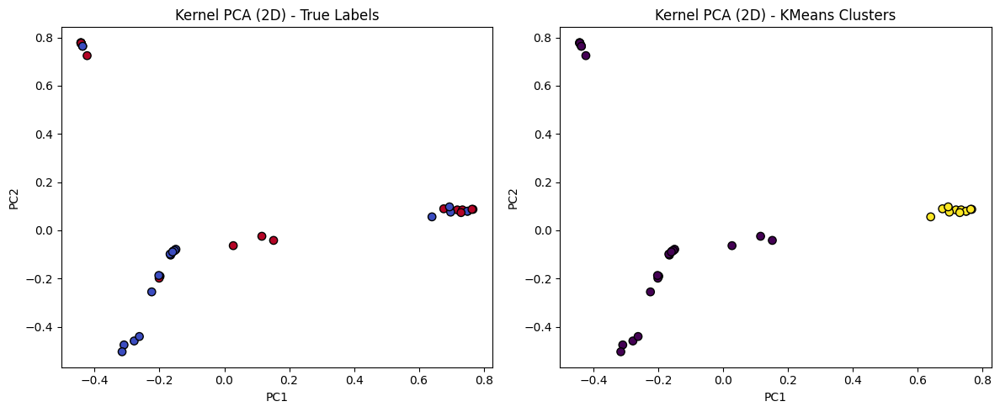

In [10]:
import matplotlib.pyplot as plt
from sklearn.decomposition import KernelPCA

# 2D projection from your precomputed kernel
kpca_vis = KernelPCA(n_components=2, kernel="precomputed", random_state=42)
X_train_2d = kpca_vis.fit_transform(kts)   # K_train: (n_train, n_train)
X_test_2d = kpca_vis.transform(kts_test)         # K_test: (n_test, n_train)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Left: true labels
s1 = ax[0].scatter(X_test_2d[:, 0], X_test_2d[:, 1], c=y_test_bin, cmap="coolwarm", s=45, edgecolor="k")
ax[0].set_title("Kernel PCA (2D) - True Labels")
ax[0].set_xlabel("PC1")
ax[0].set_ylabel("PC2")

# Right: KMeans cluster assignments
s2 = ax[1].scatter(X_test_2d[:, 0], X_test_2d[:, 1], c=test_clusters, cmap="viridis", s=45, edgecolor="k")
ax[1].set_title("Kernel PCA (2D) - KMeans Clusters")
ax[1].set_xlabel("PC1")
ax[1].set_ylabel("PC2")

plt.tight_layout()
plt.show()
